# Colombia Seismic Analysis Dashboard

## Objetivo

Analizar la actividad sísmica registrada en Colombia mediante técnicas de análisis exploratorio de datos (EDA) y visualización interactiva en Power BI, con el fin de identificar patrones espaciales, temporales y geológicos relacionados con la ocurrencia de eventos sísmicos.

## Fuente de Datos

Datos obtenidos del Servicio Geológico Colombiano (SGC).

Fuente oficial:
[Catálogo de Sismos del SGC](https://www.sgc.gov.co/catalogo)

Los datos originales no se distribuyen en este repositorio y deben descargarse directamente desde la fuente oficial.

## Conjunto de Datos descargado cuya fuente es el SGS tiene las siguientes caracteristicas:

- Registros: 407067
- Variables: 18
- intervalo: 1/06/1993 hasta 16/11/2026

## Alcance del Proyecto

Este proyecto se centra en:

- Analizar la distribución geográfica de los eventos sísmicos en Colombia.
- Identificar las zonas con mayor actividad sísmica.
- Evaluar la distribución de magnitudes y profundidades.
- Analizar la evolución temporal de la actividad sísmica.
- Explorar la relación entre magnitud y profundidad.
- Construir un dashboard geoespacial e interactivo en Power BI para apoyar la interpretación de los datos.

## Descripción General de los Datos

El conjunto de datos contiene registros históricos de eventos sísmicos localizados dentro del territorio colombiano y zonas cercanas, recopilados y publicados por el Servicio Geológico Colombiano (SGC).

Cada registro corresponde a un evento sísmico e incluye información relacionada con:

- Ubicación geográfica (latitud y longitud).
- Fecha y hora del evento.
- Magnitud del sismo.
- Profundidad del evento.
- Tipo de magnitud calculada.
- Agencia responsable del reporte.

## Fuente de Datos

Datos obtenidos del Servicio Geológico Colombiano (SGC).

# Estructura del Proyecto

1. Importación de librerías
2. Limpieza de datos
3. Resumen de la evaluación inicial del conjunto de datos limpio
4. Ventana temporal de análisis e inicio del EDA
5. Preguntas de negocio a resolver

   5.1. ¿Dónde ocurre la mayor actividad sísmica en Colombia?

   5.2. ¿Cómo ha evolucionado la ocurrencia de sismos de magnitud igual o superior a 6.0?

   5.3. ¿Cuáles son las magnitudes más frecuentes?

   5.4.¿Cómo se distribuyen las profundidades de los eventos?

   5.5.¿Existe relación entre magnitud y profundidad?

   5.6.¿Qué agencias registran mayor volumen de eventos?

6. Hallazgos principales
7. Limitaciones del análisis
8. Exportación del conjunto de datos para Power BI



# 1. Importación de librerías

In [1]:
# ==================================================
# 📚 IMPORTACIÓN DE LIBRERÍAS
# ==================================================

# 📂🧹🔍📊 Librerías básicas para exploración y análisis

# Librería para trabajar con DataFrames
import pandas as pd
pd.set_option('display.max_columns', None) #Parametrizacion que permite ver todas las columnas

# Librería para carpetas
import os

# Librería para cálculos numéricos y matrices
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt      # Más personalizable
import seaborn as sns                # Más moderna y estética
import folium                        # Mapa de Folium
from folium.plugins import HeatMap   # Mapas de Calor folium


# ==================================================
# 🤖 MACHINE LEARNING - SCIKIT LEARN
# ==================================================

# 📈 Modelos de regresión
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# 🔗 Pipeline (cadena de transformaciones)
from sklearn.pipeline import Pipeline

# ⚖️ Escalado de variables
from sklearn.preprocessing import StandardScaler

# 📏 Métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score

# ✂️ División de datos
from sklearn.model_selection import train_test_split

# ✅ Validación cruzada
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

# 🛡️ Regresión Ridge para reducir el sobreajuste
from sklearn.linear_model import Ridge

# 🔍 Búsqueda de hiperparámetros
from sklearn.model_selection import GridSearchCV

# 🔍 Generacion de cluster
from sklearn.cluster import DBSCAN

# 📊 Herramienta para normalizar
from sklearn.preprocessing import MinMaxScaler

In [2]:
# Carga y copia del conjunto de datos

df = pd.read_csv('../Data/Raw/20261116_205614_2ed2cc4d-5104-4dc5-a7ed-57b9acb89685.csv') 			#read_csv Modulo para cargar archivos, se carga sin títulos,
										                                #el Header = none, hace que no se tome la primera fila para tomar titulo

df_cl = df.copy()							                           	#Modulo para copia de datos

In [3]:
df_cl.info()

<class 'pandas.DataFrame'>
RangeIndex: 407067 entries, 0 to 407066
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               407067 non-null  str    
 1   status           407067 non-null  str    
 2   rms              407064 non-null  float64
 3   agency           407067 non-null  str    
 4   gap              406872 non-null  float64
 5   place            407067 non-null  str    
 6   local_time       407067 non-null  str    
 7   utc_time         407067 non-null  str    
 8   magnitude        407067 non-null  float64
 9   magnitude_error  221710 non-null  float64
 10  nst              407065 non-null  float64
 11  mag_type         407067 non-null  str    
 12  latitude         407067 non-null  float64
 13  latitude_error   406802 non-null  float64
 14  longitude        407067 non-null  float64
 15  longitude_error  406802 non-null  float64
 16  depth            407067 non-null  int64  
 17  de

In [4]:
#Link de descarga https://www.sgc.gov.co/catalogo, en un rango de fechas del 1 de junio de 1993 hasta 16-11-2026

# 2. Limpieza de datos

In [5]:

#Las siguientes variables fueron eliminadas porque
#están asociadas a métricas de incertidumbre y calidad
#del dato, las cuales no hacen parte del alcance
#analítico definido para el proyecto.



df_cl = df_cl.drop(columns=["status", "latitude_error", "longitude_error", "depth_error",
                          "magnitude_error", "rms", "nst", "gap", "utc_time"])


In [6]:
#Conversion de datos

df_cl["agency"] = df_cl["agency"].astype("category")                                    #Se convierte las siguietnes variables en categoricas.
df_cl["local_time"] = pd.to_datetime(df_cl["local_time"],format="%Y-%m-%d %H:%M:%S")    #Se da formato de fecha a la columna e tiempo.

df_cl["year"] = df_cl["local_time"].dt.year

Se crean intervalos para clasificar las magnitudes de los sismos

| Magnitud | Clasificación |
|-----------|-----------|
| < 2.0 | Micro sismo |
| 2.0 - 2.9 | Muy menor |
| 3.0 - 3.9 | Menor |
| 4.0 - 4.9 | Ligero |
| 5.0 - 5.9 | Moderado |
| 6.0 - 6.9 | Fuerte |
| 7.0 - 7.9 | Mayor |
| ≥ 8.0 | Gran terremoto |

In [7]:
# Cracion de los bins para agrupar las magnitudes de las magnitudes

bins = [-2, 2, 3, 4, 5, 6, 7, 8, 10]				#Se genera los intervalos de los bins

labels = [
    "Micro sismo",
    "Muy menor",
    "Menor",
    "Ligero",
    "Moderado",
    "Fuerte",
    "Mayor",
    "Gran terremoto"
]								#Se crea las Categorías de los Bins

df_cl["magnitude_class"] = pd.cut(				#Se crea la Columna categoría con los bins

    df_cl["magnitude"],
    bins=bins,
    labels=labels
)

# Se crea columna de rango de acuerdo a los bins creados


labels = [
    "< 2.0",
    "2.0 - 2.9",
    "3.0 - 3.9",
    "4.0 - 4.9",
    "5.0 - 5.9",
    "6.0 - 6.9",
    "7.0 - 7.9",
    "≥ 8.0"
]								#Se crea las Categorías de los Bins



df_cl["range"]  = pd.cut(				#Se crea la Columna categoría con los bins

    df_cl["magnitude"],
    bins=bins,
    labels=labels
)



In [8]:
# Creacion de columna de normalizacion de magnitudes

scaler = MinMaxScaler()							#Funcion de escalamiento o normalización de 0 a 1

df_cl["magnitude_norm"] = scaler.fit_transform(				#Creacion de columna normalizada
    df_cl[["magnitude"]]							#Columna a normalizar
)


In [9]:
# creacion de columna de magnitud en julius

df_cl["energy_joules"] = 10 ** (
    1.5 * df_cl["magnitude"] + 4.8
)


df_cl["energy_joules_norm"] = scaler.fit_transform(				#Creacion de columna normalizada
    df_cl[["energy_joules"]]							#Columna a normalizar
)


In [10]:
df_cl.info()

<class 'pandas.DataFrame'>
RangeIndex: 407067 entries, 0 to 407066
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   id                  407067 non-null  str           
 1   agency              407067 non-null  category      
 2   place               407067 non-null  str           
 3   local_time          407067 non-null  datetime64[us]
 4   magnitude           407067 non-null  float64       
 5   mag_type            407067 non-null  str           
 6   latitude            407067 non-null  float64       
 7   longitude           407067 non-null  float64       
 8   depth               407067 non-null  int64         
 9   year                407067 non-null  int32         
 10  magnitude_class     407067 non-null  category      
 11  range               407067 non-null  category      
 12  magnitude_norm      407067 non-null  float64       
 13  energy_joules       407067 non-null  flo

In [11]:
df_cl

,id,agency,place,local_time,magnitude,mag_type,latitude,longitude,depth,year,magnitude_class,range,magnitude_norm,energy_joules,energy_joules_norm
0,SGC2026wouxlk,SGC,"Chaparral - Tolima, Colombia",2026-11-16 11:13:15,1.5,MLr_2,3.8028,-75.6609,13,2026,Micro sismo,< 2.0,0.301075,1.122018e+07,1.778167e-10
1,SGC2026wouopr,SGC,"Guadalupe - Santander, Colombia",2026-11-16 11:02:59,2.4,MLr_3,6.1843,-73.4649,136,2026,Muy menor,2.0 - 2.9,0.397849,2.511886e+08,3.981060e-09
2,SGC2026wougcl,SGC,"Puracé (Coconuco) - Cauca, Colombia",2026-11-16 10:53:08,1.7,MLr_2,2.3339,-76.4600,1,2026,Micro sismo,< 2.0,0.322581,2.238721e+07,3.548022e-10
3,SGC2026wotnut,SGC,"Chaparral - Tolima, Colombia",2026-11-16 10:31:54,1.2,MLr_2,3.8303,-75.6226,7,2026,Micro sismo,< 2.0,0.268817,3.981072e+06,6.308451e-11
4,SGC2026wotneu,SGC,"Chaparral - Tolima, Colombia",2026-11-16 10:31:11,0.8,MLr_2,3.8353,-75.6925,5,2026,Micro sismo,< 2.0,0.225806,1.000000e+06,1.583771e-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
407062,SGC1993isyaxg,SGC,"Los Santos - Santander, Colombia",1993-06-01 11:07:52,3.1,ML,6.7900,-73.0770,152,1993,Menor,3.0 - 3.9,0.473118,2.818383e+09,4.466835e-08
407063,SGC1993jbkxfg,SGC,"Jordán Sube - Santander, Colombia",1993-06-01 10:31:24,4.4,ML,6.7540,-73.0580,150,1993,Ligero,4.0 - 4.9,0.612903,2.511886e+11,3.981072e-06
407064,SGC1993ikrach,SGC,"Betulia - Santander, Colombia",1993-06-01 05:34:45,2.9,ML,6.8940,-73.1710,150,1993,Muy menor,2.0 - 2.9,0.451613,1.412538e+09,2.238720e-08
407065,SGC1993ptmotn,SGC,"Los Santos - Santander, Colombia",1993-06-01 05:13:18,2.9,ML,6.8390,-73.1050,152,1993,Muy menor,2.0 - 2.9,0.451613,1.412538e+09,2.238720e-08


# 3. Resumen de la evaluación inicial del conjunto de datos limpio

El conjunto de datos limpio contiene:

407.067 registros
10 variables
Todas las variables fueron revisadas y clasificadas de acuerdo con su relevancia para el negocio, calidad de los datos y utilidad analítica.

El diccionario de datos detallado fue documentado por separado.

### Resumen de la clasificación de variables

| Categoría | Número de Variables |
|----------|----------|
| Variables alfanumericas | 3 |
| Campos de Fecha | 2 |
| Variables Categóricas | 1 |
| Variables Booleanas | 0 |
| Métricas Operativas | 4 |


### Principales observaciones

- La información disponible cubre más de 30 años de actividad sísmica registrada en Colombia.
- El conjunto de datos no presenta problemas significativos de completitud en las variables seleccionadas para el análisis.
- Las variables de ubicación, magnitud, profundidad y tiempo constituyen los principales ejes analíticos del proyecto.

### Documentación de referencia

Se realizó una revisión detallada de las 18 variables orignales del conjunto de datos. El diccionario de datos completo fue documentado por separado y se encuentra disponible dentro de la carpeta Data/Processed archivo excel "Diccionario de datos.xlsx" como soporte metodológico para las decisiones de limpieza, transformación y análisis realizadas en este proyecto

# 4. Ventana temporal de análisis es inicio del EDA

El conjunto de datos abarca desde 1 de junio de 1993 hasta 16-11-2026, por lo cual se utilizara la totalidad de la fuente.

El objetivo es usar todos los datos disponibles para determiar de manera mas precisa patrones de tiempo y lugar para diferentes graficos

# 5. Preguntas de negocio a resolver

# 5.1. ¿Dónde ocurre la mayor actividad sísmica en Colombia?

In [12]:
# Para el procesamiento de datos se genera una muestra de 16000 datos aletorios de los 407067 datos disponibles

df_sample = df_cl.sample(				#Creacion de una muestra
    n=16000,							#Numero de la muestra
    random_state=42						#Semilla de la aleatoriedad
)


In [13]:
# se pretende realizar un modelo no supervisado para generar cluster utilizando en este caso un EPS de 0.07 que equivaldria aproximadamente
# a 7K de radio de los cluster

coords = df_sample[["latitude","longitude"]]

modelo = DBSCAN(
    eps=0.07,						#Distancia máxima para considerar que dos puntos son vecinos.
    min_samples=20					#Numero minimio de  eventos cercanos para el cluster
)

df_sample["cluster"] = modelo.fit_predict(coords)		#Creador de la columna de acuerdo a la predicción del modelo

In [14]:
# Se genera un varaible que aparta los valores que no generaron cluster

df_sample_cluster = df_sample[df_sample["cluster"] != -1 ] 

df_sample_cluster


,id,agency,place,local_time,magnitude,mag_type,latitude,longitude,depth,year,magnitude_class,range,magnitude_norm,energy_joules,energy_joules_norm,cluster
35767,SGC2025smyqzu,SGC,"Los Santos - Santander, Colombia",2025-09-19 19:12:03,2.5,MLr_3,6.8011,-73.1403,148,2025,Muy menor,2.0 - 2.9,0.408602,3.548134e+08,5.623402e-09,0
406854,SGC1993aarcfv,SGC,"Los Santos - Santander, Colombia",1993-06-18 20:53:06,3.3,ML,6.8410,-73.0500,150,1993,Menor,3.0 - 3.9,0.494624,5.623413e+09,8.912508e-08,0
192850,SGC2019obzvj,SGC,"Los Santos - Santander, Colombia",2019-07-20 01:39:09,1.6,MLr_3,6.7926,-73.1655,147,2019,Micro sismo,< 2.0,0.311828,1.584893e+07,2.511774e-10,0
235977,SGC2017egpbyd,SGC,"Zapatoca - Santander, Colombia",2017-06-09 04:53:15,1.7,ML,6.8010,-73.1990,149,2017,Micro sismo,< 2.0,0.322581,2.238721e+07,3.548022e-10,0
294211,SGC2013cldeej,SGC,"Cucunubá - Cundinamarca, Colombia",2013-09-30 07:43:23,2.1,ML,5.2700,-73.7660,141,2013,Muy menor,2.0 - 2.9,0.365591,8.912509e+07,1.412526e-09,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
220269,SGC2018ifaw,SGC,"Zapatoca - Santander, Colombia",2018-04-27 09:24:12,2.0,MLr_3,6.8275,-73.2028,146,2018,Micro sismo,< 2.0,0.354839,6.309573e+07,9.999888e-10,0
122755,SGC2022lhagho,SGC,"Aratoca - Santander, Colombia",2022-06-09 09:58:36,1.7,MLr_3,6.7591,-73.0486,151,2022,Micro sismo,< 2.0,0.322581,2.238721e+07,3.548022e-10,0
319,SGC2026wixdih,SGC,"Aratoca - Santander, Colombia",2026-11-13 05:53:36,2.3,MLr_3,6.7046,-73.0738,136,2026,Muy menor,2.0 - 2.9,0.387097,1.778279e+08,2.818372e-09,0
193901,SGC2019mwffx,SGC,"Los Santos - Santander, Colombia",2019-07-02 16:07:17,2.0,MLr_3,6.8343,-73.1683,141,2019,Micro sismo,< 2.0,0.354839,6.309573e+07,9.999888e-10,0


In [15]:
mapa = folium.Map(
    location=[4.5, -74],
    zoom_start=5
)

HeatMap(
    df_sample_cluster[["latitude", "longitude"]].values.tolist(),
    radius=10
).add_to(mapa)

mapa

In [16]:
(df_sample_cluster["place"].value_counts(normalize=True)*100).head(10)

place
Los Santos - Santander, Colombia     42.176301
Zapatoca - Santander, Colombia        8.582333
Cepitá - Santander, Colombia          4.570418
Villanueva - Santander, Colombia      3.015917
Dabeiba - Antioquia, Colombia         2.885600
Mesetas - Meta, Colombia              2.094387
Chaparral - Tolima, Colombia          1.154240
Betulia - Santander, Colombia         1.089081
El Playón - Santander, Colombia       0.949455
Cucunubá - Cundinamarca, Colombia     0.940147
Name: proportion, dtype: float64

Dado la exploracion realizada se encuentra que la region con mas representacion de sismos en los ultimos 30 años es la zona de Los santos - Santander. seguido de las siguientes ciudades en proporcion porcentual

- Los Santos - Santander, Colombia     42.176301
- Zapatoca - Santander, Colombia        8.582333
- Cepitá - Santander, Colombia          4.570418
- Villanueva - Santander, Colombia      3.015917
- Dabeiba - Antioquia, Colombia         2.885600
- Mesetas - Meta, Colombia              2.094387
- Chaparral - Tolima, Colombia          1.154240
- Betulia - Santander, Colombia         1.089081
- El Playón - Santander, Colombia       0.949455
- Cucunubá - Cundinamarca, Colombia     0.940147

El clustering espacial se realizó sobre una muestra aleatoria del catálogo sísmico con el objetivo de reducir el costo computacional del algoritmo DBSCAN.

Por lo anterior, los clústeres identificados deben interpretarse como aproximaciones de las principales regiones de concentración sísmica y no como una segmentación exhaustiva de la totalidad de los eventos.


In [17]:
df_cl["magnitude_class"].value_counts()

magnitude_class
Micro sismo       274258
Muy menor         109544
Menor              20162
Ligero              2694
Moderado             356
Fuerte                47
Mayor                  6
Gran terremoto         0
Name: count, dtype: int64

# 5.2. ¿Cómo ha evolucionado la ocurrencia de sismos de magnitud igual o superior a 6.0?

In [18]:
df_big_sis = df_cl[(df_cl["magnitude_class"].isin(["Fuerte","Mayor", "Gran terremoto"])) & (df_cl["place"].str.contains("Colombia"))]

Text(0, 0.5, 'CHARGES')

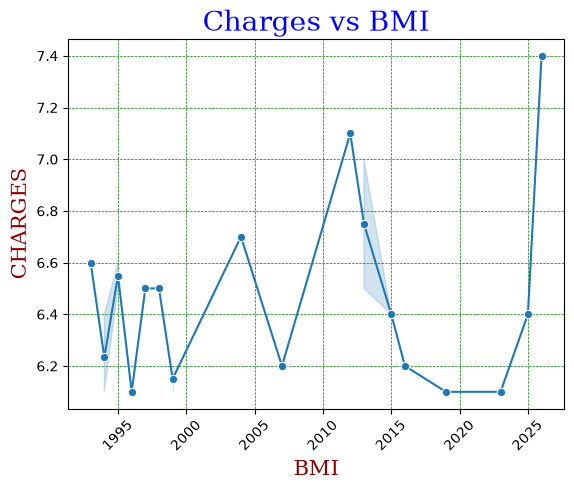

In [19]:
plt.grid(color = 'green', linestyle = '--', linewidth = .5)     #Refeire a la malla

sns.lineplot(
    data=df_big_sis,                                      #Base de datos fuente
    x="year",                                              #Columna de datos para X
    y="magnitude",                                                  #Columna de datos para Y
    marker="o"                                                  #Simbolo de los puntos
)

font1 = {'family':'serif','color':'blue','size':20}             #Diccionario para personalizador de label
font2 = {'family':'serif','color':'darkred','size':15}          #Diccionario para personalizador de label

plt.title("Charges vs BMI", fontdict = font1)                   #Titulo del Grafico
plt.xlabel("BMI", fontdict = font2)                             #Titulo en X
plt.xticks(rotation=45)                                         #Para rotar el eje X
plt.ylabel("CHARGES", fontdict = font2)                         #Titulo en Y


In [20]:
# Se genera el siguiente grafico para determinar la ubicacion geografica de los sismos mas fuertes en los ultimos años

mapa = folium.Map(
    location=[4.5, -74],
    zoom_start=6
)

HeatMap(
    df_big_sis[["latitude", "longitude","energy_joules"]].values.tolist(),
    radius=11
).add_to(mapa)

mapa

# 5.3. ¿Cuáles son las magnitudes más frecuentes?

In [ ]:
# ser realiza el calculo relativo de las frecuencias sismicas de acuerdo a su magnitud
df_cl.groupby(["magnitude_class","range"])["year"].count()/(df_cl["year"].count())*100

magnitude_class  range    
Micro sismo      < 2.0        67.374167
Muy menor        2.0 - 2.9    26.910558
Menor            3.0 - 3.9     4.952993
Ligero           4.0 - 4.9     0.661808
Moderado         5.0 - 5.9     0.087455
Fuerte           6.0 - 6.9     0.011546
Mayor            7.0 - 7.9     0.001474
Name: year, dtype: float64

In [104]:
# se realiza calculo del porcentaje de sismos mayores a magnitud 4
df_calc = (df_cl.groupby(["magnitude_class","range"])["year"].count()/(df_cl["year"].count())*100).reset_index()
df_calc["year"][df_calc["year"]<1].sum()

np.float64(0.7622823761199017)

In [ ]:
#como se logra evidenciar en la tabal anterior en los ultimos 30 años los sismos mas fruentes corresponden a microsismos, 
# que corresponden maginutudes menores a 2 en una proporciondel 67% del total de los datos, seguido de un 26% de magnitudes entre 2.0 y 2.9
# por lo tanto se concluye que los sismos con maginitudes superiores a magnitud a 4 son muy infrecuentes dado que corresponden al 0.76% del total registrado

# 5.4.¿Cómo se distribuyen las profundidades de los eventos?

# 5.5.¿Existe relación entre magnitud y profundidad?

# 5.6.¿Qué agencias registran mayor volumen de eventos?

# 6. Hallazgos Principales

# 7. Limitaciones del Análisis

# 8. Exportación del conjunto de datos para Power BI